In [ ]:
!pip -q install "qiskit>=2.0,<3" qiskit-aer opencv-python-headless matplotlib pillow pylatexenc

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
from google.colab import files
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import CDKMRippleCarryAdder
from qiskit.quantum_info import Statevector
print("All libraries imported successfully!")
print("Qiskit version:", __import__("qiskit").__version__)
print("OpenCV version:", cv2.__version__)

All libraries imported successfully!
Qiskit version: 2.6.1
OpenCV version: 4.14.0


Upload your image


Saving Monochrome Lena Edge Detection Portrait.png to Monochrome Lena Edge Detection Portrait.png
Image uploaded successfully: Monochrome Lena Edge Detection Portrait.png


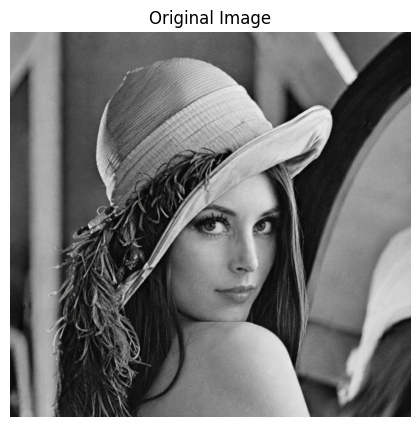

In [ ]:
print("Upload your image")
uploaded = files.upload()
if not uploaded:
    raise ValueError("No image uploaded!")
image_name = next(iter(uploaded))
image_bytes = np.frombuffer(
    uploaded[image_name],
    dtype=np.uint8
)
original_image = cv2.imdecode(
    image_bytes,
    cv2.IMREAD_COLOR
)
if original_image is None:
    raise ValueError("Unable to read uploaded image!")
print("Image uploaded successfully:", image_name)
# Display original image
plt.figure(figsize=(7, 5))
plt.imshow(
    cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
)
plt.title("Original Image")
plt.axis("off")
plt.show()

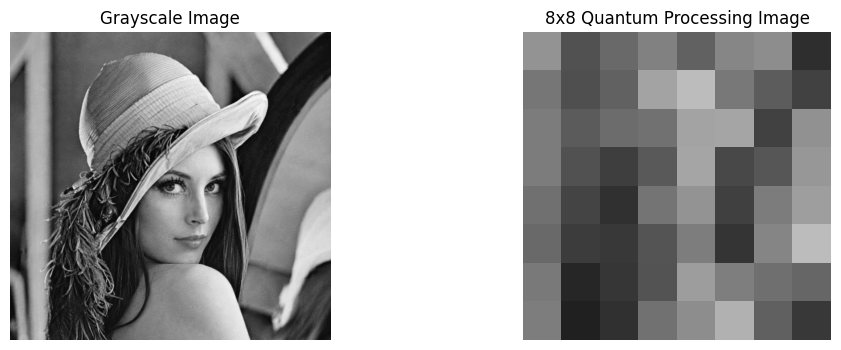

Image dimensions: (8, 8)

Pixel intensity matrix:
[[147  82 105 129  97 134 141  46]
 [118  79  98 163 188 120  92  65]
 [124  91 108 113 164 165  65 145]
 [124  81  62  89 165  72  86 151]
 [112  68  49 116 148  64 124 158]
 [105  60  56  84 125  53 133 188]
 [122  38  54  83 157 126 111 102]
 [125  33  49 114 141 177  96  56]]


In [ ]:
# Convert original image to grayscale
gray_image = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2GRAY
)
# Resize image to 8x8
small_image = cv2.resize(
    gray_image,
    (8, 8),
    interpolation=cv2.INTER_AREA
)
# Display images
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(small_image, cmap="gray", vmin=0, vmax=255)
plt.title("8x8 Quantum Processing Image")
plt.axis("off")
plt.show()
print("Image dimensions:", small_image.shape)
print("\nPixel intensity matrix:")
print(small_image)

In [ ]:
def create_neqr_circuit(image):
    height, width = image.shape
    if height != 8 or width != 8:
        raise ValueError("NEQR demonstration requires an 8x8 image")
    # Quantum registers
    x_reg = QuantumRegister(3, "X")
    y_reg = QuantumRegister(3, "Y")
    intensity_reg = QuantumRegister(8, "Intensity")
    qc = QuantumCircuit(
        x_reg,
        y_reg,
        intensity_reg
    )
    # Create superposition of all pixel positions
    qc.h(x_reg)
    qc.h(y_reg)
    controls = list(x_reg) + list(y_reg)
    # Encode each pixel intensity
    for y in range(8):
        for x in range(8):
            pixel_value = int(image[y, x])
            # Convert intensity into binary representation
            binary_value = format(pixel_value, "08b")
            # Qubit order is least-significant bit first
            for bit in range(8):
                if (pixel_value >> bit) & 1:
                    address_bits = (
                        [(x >> i) & 1 for i in range(3)]
                        +
                        [(y >> i) & 1 for i in range(3)]
                    )
                    # Convert zero-controls into positive controls
                    for control, value in zip(
                        controls,
                        address_bits
                    ):
                        if value == 0:
                            qc.x(control)
                    # Controlled intensity encoding
                    qc.mcx(
                        controls,
                        intensity_reg[bit]
                    )
                    # Restore address qubits
                    for control, value in zip(
                        controls,
                        address_bits
                    ):
                        if value == 0:
                            qc.x(control)
    return qc
neqr_circuit = create_neqr_circuit(small_image)
print("NEQR Quantum Image Encoding")
print("Total qubits:", neqr_circuit.num_qubits)
print("Total quantum gates:", neqr_circuit.size())
display(
    neqr_circuit.draw(
        output="mpl",
        fold=120,
        idle_wires=False
    )
)

NEQR Quantum Image Encoding
Total qubits: 14
Total quantum gates: 1718


In [ ]:
def create_reversible_subtractor(a, b, n=8):
    mask = (1 << n) - 1
    a = int(a)
    b = int(b)
    if not (0 <= a <= mask and 0 <= b <= mask):
        raise ValueError("Input must fit in the selected bit width")
    # Create a full ripple-carry adder
    adder = CDKMRippleCarryAdder(
        n,
        kind="full"
    )
    qc = QuantumCircuit(adder.num_qubits)
    # Register layout:
    #
    # q[0]       = Carry-in
    # q[1:1+n]   = A register
    # q[1+n:1+2n] = B register
    # q[-1]      = Carry-out
    # Initialize A register
    for i in range(n):
        if (a >> i) & 1:
            qc.x(1 + i)
    # Initialize one's complement of B
    b_complement = (~b) & mask
    for i in range(n):
        if (b_complement >> i) & 1:
            qc.x(1 + n + i)
    # Set carry-in to 1
    qc.x(0)
    # Perform reversible addition
    qc.compose(
        adder,
        inplace=True
    )
    return qc
def simulate_reversible_subtraction(a, b, n=8):
    mask = (1 << n) - 1
    # For absolute difference, put the larger operand first.
    # The comparison is classical; the subtraction is quantum-circuit based.
    a = int(a)
    b = int(b)
    larger = max(a, b)
    smaller = min(a, b)
    qc = create_reversible_subtractor(
        larger,
        smaller,
        n
    )
    # Exact statevector simulation
    state = Statevector.from_instruction(qc)
    # The circuit has a deterministic computational-basis output
    probabilities = np.abs(state.data) ** 2
    basis_index = int(np.argmax(probabilities))
    # Extract the output B register
    result = (
        basis_index >> (1 + n)
    ) & mask
    # Extract original A register to verify preservation
    preserved_a = (
        basis_index >> 1
    ) & mask
    if preserved_a != larger:
        raise RuntimeError("Input register A was not preserved!")
    if result != larger - smaller:
        raise RuntimeError("Quantum subtraction verification failed!")
    return result, qc

Reversible Quantum Subtraction Test
A = 180
B = 75
Expected result = 105
Quantum circuit result = 105

Subtractor circuit:


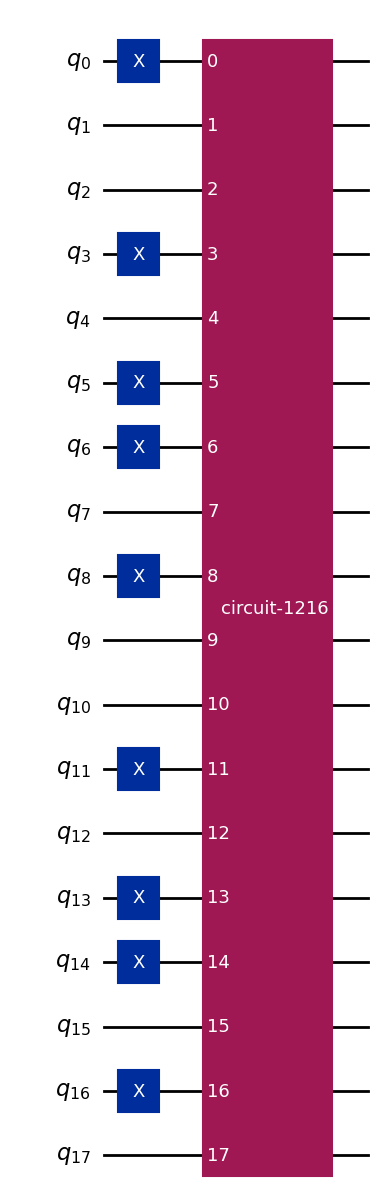

In [ ]:
a = 180
b = 75
result, subtractor_circuit = simulate_reversible_subtraction(
    a,
    b
)
print("Reversible Quantum Subtraction Test")
print("A =", a)
print("B =", b)
print("Expected result =", abs(a - b))
print("Quantum circuit result =", result)
print("\nSubtractor circuit:")
display(
    subtractor_circuit.draw(
        output="mpl",
        fold=100
    )
)

In [ ]:
def quantum_arithmetic_edge_detection(image):
    height, width = image.shape
    gx = np.zeros((height, width), dtype=np.uint16)
    gy = np.zeros((height, width), dtype=np.uint16)
    start_time = time.time()
    total_operations = 0
    for y in range(1, height - 1):
        for x in range(1, width - 1):
            # Horizontal pixel difference
            left = int(image[y, x - 1])
            right = int(image[y, x + 1])
            horizontal, _ = simulate_reversible_subtraction(
                left,
                right
            )
            gx[y, x] = horizontal
            # Vertical pixel difference
            top = int(image[y - 1, x])
            bottom = int(image[y + 1, x])
            vertical, _ = simulate_reversible_subtraction(
                top,
                bottom
            )
            gy[y, x] = vertical
            total_operations += 2
    # Calculate gradient magnitude
    magnitude = gx + gy
    # Normalize the result
    magnitude = cv2.normalize(
        magnitude.astype(np.float32),
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )
    magnitude = magnitude.astype(np.uint8)
    execution_time = time.time() - start_time
    return (
        gx,
        gy,
        magnitude,
        total_operations,
        execution_time
    )
print("Starting quantum-arithmetic-assisted edge detection...")
(
    quantum_gx,
    quantum_gy,
    quantum_magnitude,
    total_quantum_operations,
    quantum_execution_time
) = quantum_arithmetic_edge_detection(small_image)
print("Quantum arithmetic edge detection completed!")
print("Reversible subtraction operations:",total_quantum_operations)
print("Execution time:",round(quantum_execution_time, 4),"seconds")

Starting quantum-arithmetic-assisted edge detection...
Quantum arithmetic edge detection completed!
Reversible subtraction operations: 72
Execution time: 19.9429 seconds


In [ ]:
def classical_sobel_edge_detection(image):
    start_time = time.time()
    gx = cv2.Sobel(
        image,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )
    gy = cv2.Sobel(
        image,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )
    magnitude = np.sqrt(
        gx ** 2 + gy ** 2
    )
    magnitude = cv2.normalize(
        magnitude,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )
    magnitude = magnitude.astype(np.uint8)
    execution_time = time.time() - start_time
    return gx, gy, magnitude, execution_time
(
    classical_gx,
    classical_gy,
    classical_magnitude,
    classical_execution_time
) = classical_sobel_edge_detection(small_image)
print("Classical Sobel edge detection completed!")
print("Execution time:",round(classical_execution_time, 6),"seconds")

Classical Sobel edge detection completed!
Execution time: 0.000152 seconds


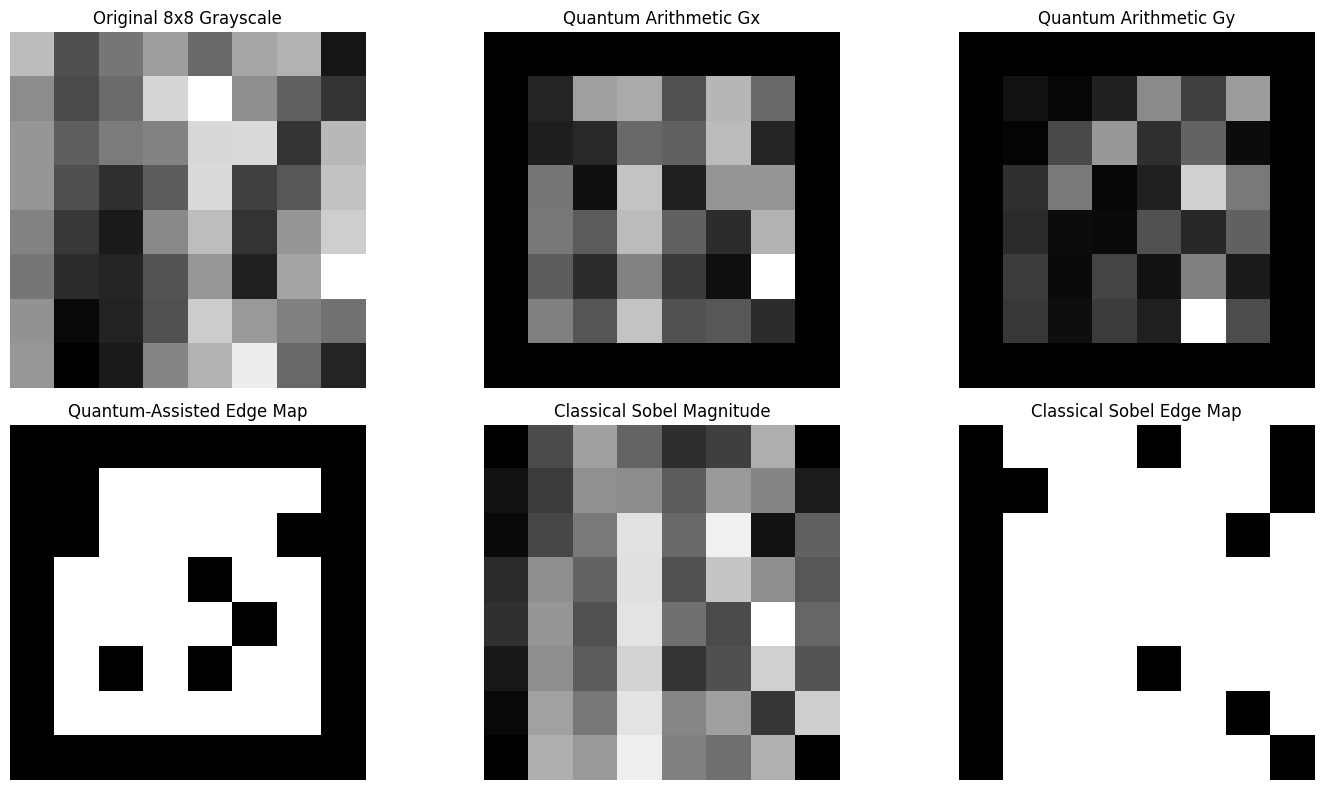

In [ ]:
THRESHOLD = 60
# Quantum arithmetic-assisted edges
_, quantum_edges = cv2.threshold(
    quantum_magnitude,
    THRESHOLD,
    255,
    cv2.THRESH_BINARY
)
# Classical Sobel edges
_, classical_edges = cv2.threshold(
    classical_magnitude,
    THRESHOLD,
    255,
    cv2.THRESH_BINARY
)
# Display results
plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 1)
plt.imshow(small_image, cmap="gray")
plt.title("Original 8x8 Grayscale")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(quantum_gx, cmap="gray")
plt.title("Quantum Arithmetic Gx")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(quantum_gy, cmap="gray")
plt.title("Quantum Arithmetic Gy")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(quantum_edges, cmap="gray")
plt.title("Quantum-Assisted Edge Map")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(classical_magnitude, cmap="gray")
plt.title("Classical Sobel Magnitude")
plt.axis("off")
plt.subplot(2, 3, 6)
plt.imshow(classical_edges, cmap="gray")
plt.title("Classical Sobel Edge Map")
plt.axis("off")
plt.tight_layout()
plt.show()

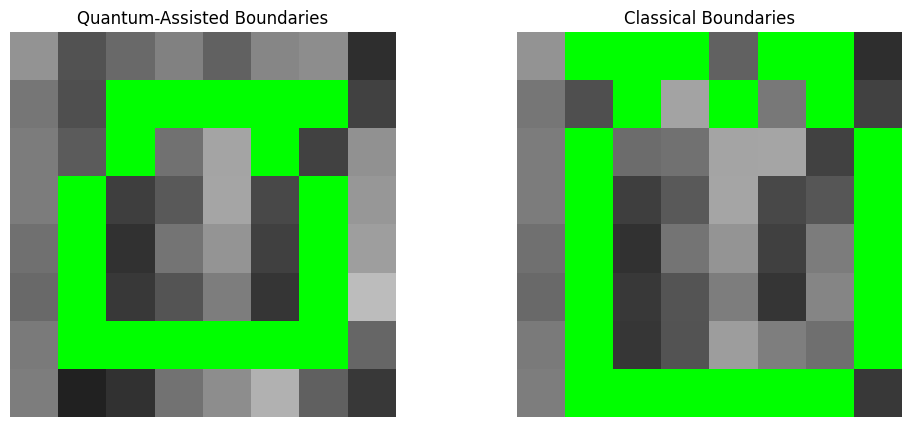

Quantum-assisted contours: 1
Classical contours: 1


In [ ]:
def extract_boundaries(edge_image, original):
    contours, hierarchy = cv2.findContours(
        edge_image.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    output = cv2.cvtColor(
        original,
        cv2.COLOR_GRAY2BGR
    )
    cv2.drawContours(
        output,
        contours,
        -1,
        (0, 255, 0),
        1
    )
    return output, contours
quantum_boundary, quantum_contours = extract_boundaries(
    quantum_edges,
    small_image
)
classical_boundary, classical_contours = extract_boundaries(
    classical_edges,
    small_image
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(
    cv2.cvtColor(quantum_boundary, cv2.COLOR_BGR2RGB)
)
plt.title("Quantum-Assisted Boundaries")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(
    cv2.cvtColor(classical_boundary, cv2.COLOR_BGR2RGB)
)
plt.title("Classical Boundaries")
plt.axis("off")
plt.show()
print("Quantum-assisted contours:",len(quantum_contours))
print("Classical contours:",len(classical_contours))

In [ ]:
sample_a = 200
sample_b = 80
sample_result, sample_circuit = simulate_reversible_subtraction(
    sample_a,
    sample_b
)
print("=" * 50)
print("QUANTUM CIRCUIT PERFORMANCE")
print("=" * 50)
print("Input A:", sample_a)
print("Input B:", sample_b)
print("Output:", sample_result)
print("Total qubits:", sample_circuit.num_qubits)
print("Total gates:", sample_circuit.size())
print("Circuit depth:", sample_circuit.depth())
print("\nGate distribution:")
print(sample_circuit.count_ops())
print("\nCircuit verification:")
print(
    "Expected:",
    sample_a - sample_b
)
print(
    "Actual:",
    sample_result
)

QUANTUM CIRCUIT PERFORMANCE
Input A: 200
Input B: 80
Output: 120
Total qubits: 18
Total gates: 11
Circuit depth: 2

Gate distribution:
OrderedDict({'x': 10, 'circuit-2092': 1})

Circuit verification:
Expected: 120
Actual: 120


In [ ]:
print("=" * 65)
print("QUANTUMEDGEVISION - PERFORMANCE COMPARISON")
print("=" * 65)
print("\nCLASSICAL SOBEL")
print(
    "Execution time:",
    round(classical_execution_time, 6),
    "seconds"
)
print(
    "Detected contours:",
    len(classical_contours)
)
print("\nQUANTUM-ARITHMETIC-ASSISTED EDGE DETECTION")
print(
    "Execution time:",
    round(quantum_execution_time, 6),
    "seconds"
)
print(
    "Reversible subtraction operations:",
    total_quantum_operations
)
print(
    "Detected contours:",
    len(quantum_contours)
)
print("\nQUANTUM CIRCUIT DETAILS")
print(
    "Qubits:",
    sample_circuit.num_qubits
)
print(
    "Gates:",
    sample_circuit.size()
)
print(
    "Circuit depth:",
    sample_circuit.depth()
)
print("=" * 65)

QUANTUMEDGEVISION - PERFORMANCE COMPARISON

CLASSICAL SOBEL
Execution time: 0.000152 seconds
Detected contours: 1

QUANTUM-ARITHMETIC-ASSISTED EDGE DETECTION
Execution time: 19.942894 seconds
Reversible subtraction operations: 72
Detected contours: 1

QUANTUM CIRCUIT DETAILS
Qubits: 18
Gates: 11
Circuit depth: 2


In [ ]:
neqr_state = Statevector.from_instruction(neqr_circuit)
state_data = neqr_state.data
nonzero_indices = np.where(
    np.abs(state_data) > 1e-8
)[0]
encoding_correct = True
for index in nonzero_indices:
    # Extract quantum registers
    x = index & 7
    y = (index >> 3) & 7
    intensity = (index >> 6) & 255
    expected = int(small_image[y, x])
    if intensity != expected:
        encoding_correct = False
        break
print("=" * 50)
print("NEQR ENCODING VERIFICATION")
print("=" * 50)
print("Expected number of basis states: 64")
print("Actual number of basis states:",
      len(nonzero_indices))
print("Statevector normalization:",
      round(np.sum(np.abs(state_data)**2), 6))
print("Image encoding correct:",
      encoding_correct)
if encoding_correct:
    print("\nSUCCESS: NEQR image encoding verified!")
else:
    print("\nERROR: NEQR image encoding mismatch!")

NEQR ENCODING VERIFICATION
Expected number of basis states: 64
Actual number of basis states: 64
Statevector normalization: 1.0
Image encoding correct: True

SUCCESS: NEQR image encoding verified!


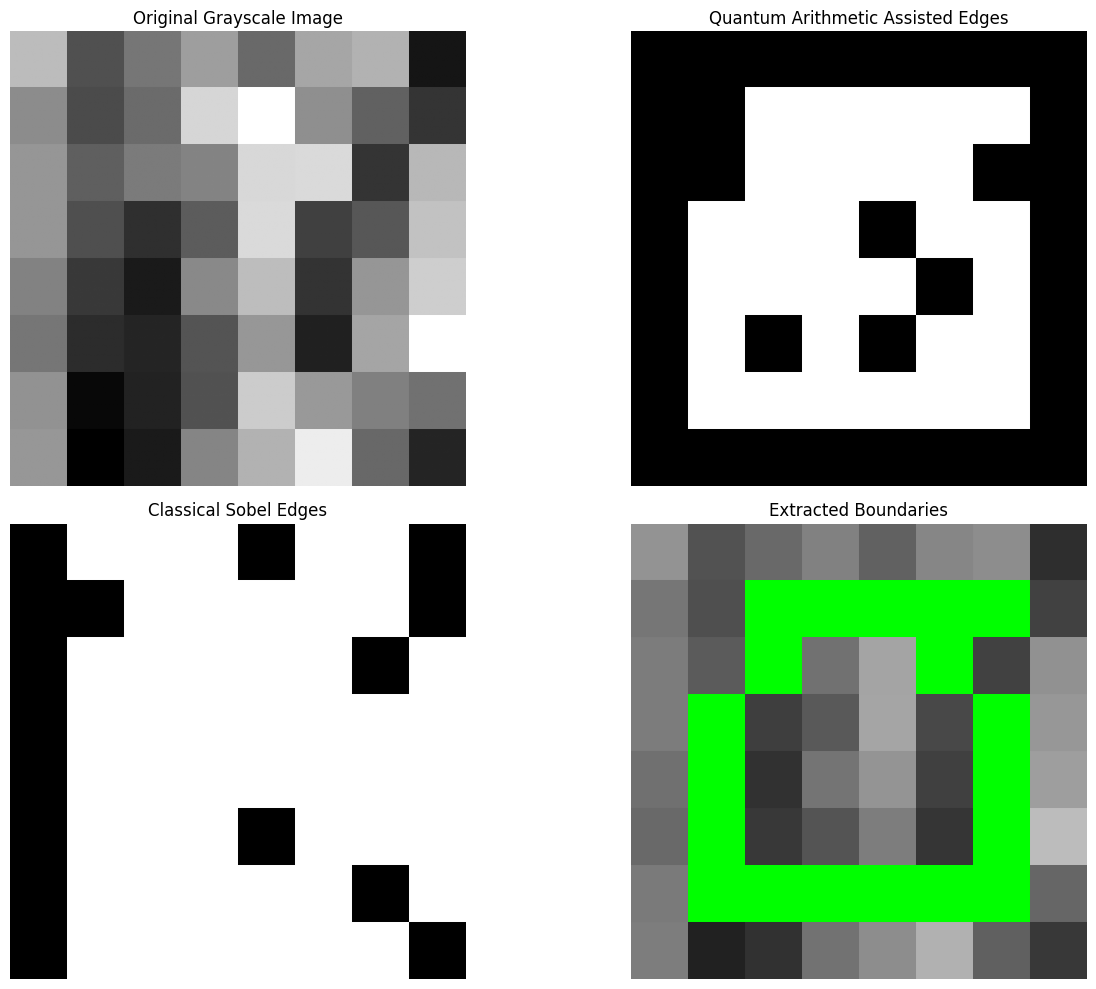

QUANTUMEDGEVISION EXECUTION COMPLETED!


In [ ]:
# Resize 8x8 results for visualization
display_size = (400, 400)
original_display = cv2.resize(
    small_image,
    display_size,
    interpolation=cv2.INTER_NEAREST
)
quantum_display = cv2.resize(
    quantum_edges,
    display_size,
    interpolation=cv2.INTER_NEAREST
)
classical_display = cv2.resize(
    classical_edges,
    display_size,
    interpolation=cv2.INTER_NEAREST
)
boundary_display = cv2.resize(
    quantum_boundary,
    display_size,
    interpolation=cv2.INTER_NEAREST
)
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.imshow(original_display, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(quantum_display, cmap="gray")
plt.title("Quantum Arithmetic Assisted Edges")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(classical_display, cmap="gray")
plt.title("Classical Sobel Edges")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(
    cv2.cvtColor(boundary_display, cv2.COLOR_BGR2RGB)
)
plt.title("Extracted Boundaries")
plt.axis("off")
plt.tight_layout()
plt.show()
print("QUANTUMEDGEVISION EXECUTION COMPLETED!")